# 🌾 Crop Recommendation System for Black Soil Regions
## Phase 1 — Machine Learning Prototype


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder

import warnings
warnings.filterwarnings('ignore')

print("✅ All libraries imported successfully.")

✅ All libraries imported successfully.


In [2]:

CSV_FILE = "Crop and fertilizer dataset.csv"   

df = pd.read_csv(CSV_FILE)

print("📐 Dataset Shape:", df.shape)
print("\n📋 Column Names:")
print(df.columns.tolist())

📐 Dataset Shape: (4513, 11)

📋 Column Names:
['District_Name', 'Soil_color', 'Nitrogen', 'Phosphorus', 'Potassium', 'pH', 'Rainfall', 'Temperature', 'Crop', 'Fertilizer', 'Link']


In [3]:

print("\n🔍 First 5 Rows:")
df.head()


🔍 First 5 Rows:


,District_Name,Soil_color,Nitrogen,Phosphorus,Potassium,pH,Rainfall,Temperature,Crop,Fertilizer,Link
0,Kolhapur,Black,75,50,100,6.5,1000,20,Sugarcane,Urea,https://youtu.be/2t5Am0xLTOo
1,Kolhapur,Black,80,50,100,6.5,1000,20,Sugarcane,Urea,https://youtu.be/2t5Am0xLTOo
2,Kolhapur,Black,85,50,100,6.5,1000,20,Sugarcane,Urea,https://youtu.be/2t5Am0xLTOo
3,Kolhapur,Black,90,50,100,6.5,1000,20,Sugarcane,Urea,https://youtu.be/2t5Am0xLTOo
4,Kolhapur,Black,95,50,100,6.5,1000,20,Sugarcane,Urea,https://youtu.be/2t5Am0xLTOo


In [4]:

print("📊 Summary Statistics:")
df.describe()

📊 Summary Statistics:


,Nitrogen,Phosphorus,Potassium,pH,Rainfall,Temperature
count,4513.000000,4513.000000,4513.000000,4513.000000,4513.000000,4513.000000
mean,95.409927,54.341901,63.595170,6.715267,819.189010,25.915134
std,38.060648,16.551991,35.691911,0.625198,251.730813,5.897328
min,20.000000,10.000000,5.000000,5.500000,300.000000,10.000000
25%,60.000000,40.000000,40.000000,6.000000,600.000000,20.000000
50%,105.000000,55.000000,55.000000,6.500000,800.000000,25.000000
75%,125.000000,65.000000,75.000000,7.000000,1000.000000,30.000000
max,150.000000,90.000000,150.000000,8.500000,1700.000000,40.000000


In [5]:
print("❓ Missing Values per Column:")
print(df.isnull().sum())

❓ Missing Values per Column:
District_Name    0
Soil_color       0
Nitrogen         0
Phosphorus       0
Potassium        0
pH               0
Rainfall         0
Temperature      0
Crop             0
Fertilizer       0
Link             0
dtype: int64


In [6]:

initial_shape = df.shape
df.dropna(inplace=True)
print(f"🧹 Rows before cleaning : {initial_shape[0]}")
print(f"✅ Rows after cleaning  : {df.shape[0]}")
print(f"   Rows removed         : {initial_shape[0] - df.shape[0]}")


df = df.applymap(lambda x: x.strip() if isinstance(x, str) else x)

print("\n📌 Column Data Types:")
print(df.dtypes)

🧹 Rows before cleaning : 4513
✅ Rows after cleaning  : 4513
   Rows removed         : 0

📌 Column Data Types:
District_Name     object
Soil_color        object
Nitrogen           int64
Phosphorus         int64
Potassium          int64
pH               float64
Rainfall           int64
Temperature        int64
Crop              object
Fertilizer        object
Link              object
dtype: object


In [7]:
# Define selected crop
selected_crops = ['Cotton', 'Jowar', 'Wheat', 'Sugarcane', 'Groundnut']


crop_col = None
for col in df.columns:
    if 'crop' in col.lower():
        crop_col = col
        break

if crop_col is None:
    raise ValueError("❌ Could not find a crop column. Please inspect df.columns and set crop_col manually.")

print(f"✅ Crop column identified: '{crop_col}'")
print(f"\n🌱 Unique crops in dataset: {df[crop_col].unique().tolist()}")

# Filter for selected crops (case-insensitive match)
df[crop_col] = df[crop_col].str.strip().str.title()
df_filtered = df[df[crop_col].isin(selected_crops)].copy()

print(f"\n📐 Filtered Dataset Shape: {df_filtered.shape}")
print(f"\n🌾 Crop Distribution:")
print(df_filtered[crop_col].value_counts())

✅ Crop column identified: 'Crop'

🌱 Unique crops in dataset: ['Sugarcane', 'Jowar', 'Cotton', 'Rice', 'Wheat', 'Groundnut', 'Maize', 'Tur', 'Urad', 'Moong', 'Gram', 'Masoor', 'Soybean', 'Ginger', 'Turmeric', 'Grapes']

📐 Filtered Dataset Shape: (3090, 11)

🌾 Crop Distribution:
Crop
Sugarcane    1010
Wheat         859
Cotton        650
Jowar         394
Groundnut     177
Name: count, dtype: int64


In [8]:
column_map = {}

for col in df_filtered.columns:
    cl = col.lower().strip()
    if cl in ['nitrogen', 'n', 'n content', 'nitrogen content']:
        column_map[col] = 'Nitrogen'
    elif cl in ['phosphorus', 'p', 'phosphorous', 'p content']:
        column_map[col] = 'Phosphorus'
    elif cl in ['potassium', 'k', 'k content']:
        column_map[col] = 'Potassium'
    elif cl in ['temperature', 'temp']:
        column_map[col] = 'Temperature'
    elif cl in ['rainfall', 'rain', 'annual rainfall']:
        column_map[col] = 'Rainfall'
    elif cl in ['ph', 'soil ph', 'ph value']:
        column_map[col] = 'pH'

df_filtered.rename(columns=column_map, inplace=True)

feature_cols = ['Nitrogen', 'Phosphorus', 'Potassium', 'Temperature', 'Rainfall', 'pH']

# Check which features are available
available_features = [f for f in feature_cols if f in df_filtered.columns]
missing_features = [f for f in feature_cols if f not in df_filtered.columns]

if missing_features:
    print(f"⚠️  Features not found and will be skipped: {missing_features}")
    print(f"   Available columns: {df_filtered.columns.tolist()}")

print(f"\n✅ Features selected: {available_features}")

X = df_filtered[available_features]
y = df_filtered[crop_col]

print(f"\n📌 Feature Matrix (X) shape : {X.shape}")
print(f"📌 Target Vector  (y) shape : {y.shape}")


✅ Features selected: ['Nitrogen', 'Phosphorus', 'Potassium', 'Temperature', 'Rainfall', 'pH']

📌 Feature Matrix (X) shape : (3090, 6)
📌 Target Vector  (y) shape : (3090,)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"📦 Training Set   : {X_train.shape[0]} samples")
print(f"🧪 Testing  Set   : {X_test.shape[0]} samples")
print(f"\n📊 Class distribution in training set:")
print(y_train.value_counts())

📦 Training Set   : 2472 samples
🧪 Testing  Set   : 618 samples

📊 Class distribution in training set:
Crop
Sugarcane    808
Wheat        687
Cotton       520
Jowar        315
Groundnut    142
Name: count, dtype: int64


In [10]:
# Initialize and train the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
accuracy = accuracy_score(y_test, y_pred)
print(f"✅ Model Accuracy : {accuracy * 100:.2f}%\n")
print("📋 Classification Report:")
print(classification_report(y_test, y_pred))

✅ Model Accuracy : 99.35%

📋 Classification Report:
              precision    recall  f1-score   support

      Cotton       1.00      0.99      1.00       130
   Groundnut       1.00      0.91      0.96        35
       Jowar       0.96      1.00      0.98        79
   Sugarcane       1.00      1.00      1.00       202
       Wheat       0.99      1.00      1.00       172

    accuracy                           0.99       618
   macro avg       0.99      0.98      0.99       618
weighted avg       0.99      0.99      0.99       618



In [13]:
# Sample input dictionary (full set of features)
sample_full = {
    'Nitrogen'    : 20,
    'Phosphorus'  : 30,
    'Potassium'   : 10,
    'Temperature' : 20,
    'Rainfall'    : 100,
    'pH'          : 6.5
}


sample_values = [sample_full[f] for f in available_features]
sample_input = pd.DataFrame([sample_values], columns=available_features)

# Predict
predicted_crop = model.predict(sample_input)[0]

print("🌱 Sample Input:")
for f in available_features:
    print(f"   {f:15s}: {sample_full[f]}")
print(f"\n🌾 Predicted Crop : ✅ {predicted_crop}")

🌱 Sample Input:
   Nitrogen       : 20
   Phosphorus     : 30
   Potassium      : 10
   Temperature    : 20
   Rainfall       : 100
   pH             : 6.5

🌾 Predicted Crop : ✅ Jowar


📊 Top 5 Crop Recommendations:
     Crop  Probability
    Jowar         0.71
Groundnut         0.29
   Cotton         0.00
Sugarcane         0.00
    Wheat         0.00


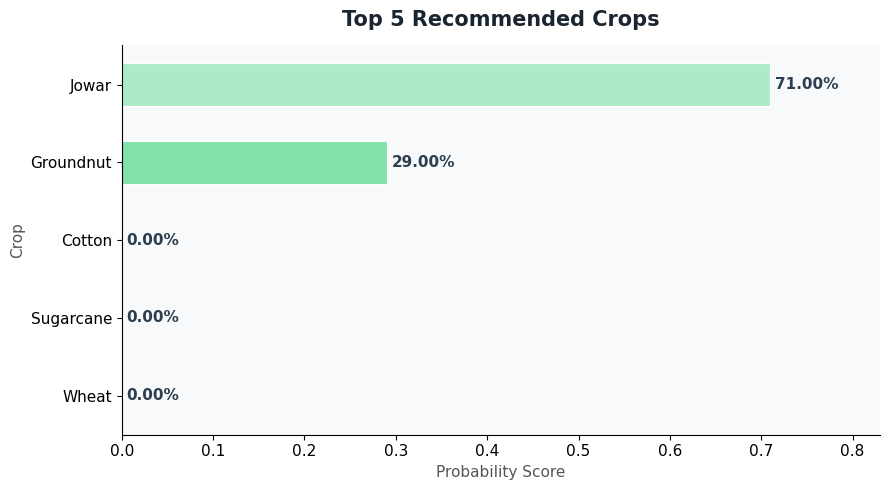


✅ Visualization saved as 'top5_crop_recommendations.png'


In [14]:

probabilities = model.predict_proba(sample_input)[0]
classes       = model.classes_


prob_df = pd.DataFrame({'Crop': classes, 'Probability': probabilities})
prob_df.sort_values('Probability', ascending=False, inplace=True)
top5 = prob_df.head(5).reset_index(drop=True)

print("📊 Top 5 Crop Recommendations:")
print(top5.to_string(index=False))

# ── Visualization 
fig, ax = plt.subplots(figsize=(9, 5))

colors = ['#2ecc71', '#27ae60', '#52be80', '#82e0aa', '#abebc6']

bars = ax.barh(
    top5['Crop'][::-1],
    top5['Probability'][::-1],
    color=colors,
    edgecolor='white',
    linewidth=0.8,
    height=0.55
)

# Add value labels on bars
for bar, val in zip(bars, top5['Probability'][::-1]):
    ax.text(
        bar.get_width() + 0.005,
        bar.get_y() + bar.get_height() / 2,
        f'{val:.2%}',
        va='center', ha='left',
        fontsize=11, fontweight='bold', color='#2c3e50'
    )

ax.set_title('Top 5 Recommended Crops', fontsize=15, fontweight='bold',
             color='#1a252f', pad=14)
ax.set_xlabel('Probability Score', fontsize=11, color='#555')
ax.set_ylabel('Crop', fontsize=11, color='#555')
ax.set_xlim(0, top5['Probability'].max() + 0.12)
ax.tick_params(axis='both', labelsize=11)
ax.spines[['top', 'right']].set_visible(False)
ax.set_facecolor('#f8f9fa')
fig.patch.set_facecolor('#ffffff')

plt.tight_layout()
plt.savefig('top5_crop_recommendations.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n✅ Visualization saved as 'top5_crop_recommendations.png'")

---
## ✅ Phase 1 — Summary

| Step | Description | Status |
|------|-------------|--------|
| 1 | Import Libraries | ✅ Done |
| 2 | Load & Explore Dataset | ✅ Done |
| 3 | Basic Data Cleaning | ✅ Done |
| 4 | Filter for 5 Crops | ✅ Done |
| 5 | Feature Selection (N, P, K, Temp, Rain, pH) | ✅ Done |
| 6 | Train / Test Split (80/20) | ✅ Done |
| 7 | Random Forest Classifier Training & Evaluation | ✅ Done |
| 8 | Example Crop Prediction | ✅ Done |
| 9 | Top 5 Crop Recommendation Visualization | ✅ Done |

**Phase 1 delivers a working ML prototype** that recommends crops based on soil and climate conditions in Black Soil regions of Western Maharashtra.

> **Next Steps (Phase 2):** Expand to all crops, add fertilizer recommendations, tune hyperparameters, deploy as a web application.